# Netflix Recommender System

**Question:** Based on a viewer's past ratings, how well can a model rank unseen movies so that the ones it predicts they'd rate highly are actually the ones they go on to rate highly?

**Background:**


**Hypothesis**

In [2]:
import pandas as pd
from pathlib import Path
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

DATA_DIR = Path(".")
DATASET = "combined_data_1.txt"


In [4]:
records = []
current_movie = None

for i in range(1, 5):
    filename = f'combined_data_{i}.txt'
    with open(DATA_DIR / filename, 'r') as f:
        for line in f:
            line = line.strip()
            if line.endswith(':'):
                current_movie = int(line[:-1])
            else:
                customer_id, rating, date = line.split(',')
                records.append((current_movie, int(customer_id), int(rating), date))

movies = pd.DataFrame(records, columns=['movie_id', 'customer_id', 'rating', 'date'])
movies['movie_id'] = movies['movie_id'].astype(np.int32)
movies['customer_id'] = movies['customer_id'].astype(np.int32)
movies['rating'] = movies['rating'].astype(np.int8)
movies['date'] = pd.to_datetime(movies['date'])

In [14]:
movies_df=movies.copy()

In [5]:
records = []
with open(DATA_DIR / 'movie_titles.csv', encoding='latin-1') as f:
    lines = f.read().splitlines()
titles_df = pd.DataFrame(lines, columns=['raw'])
titles_df[['movie_id', 'release_date', 'movie_title']] = titles_df['raw'].str.split(',', n=2, expand=True)
titles_df = titles_df.drop('raw', axis=1)
titles_df['release_date'] = pd.to_numeric(titles_df['release_date'], errors='coerce')
titles_df['movie_id'] = titles_df['movie_id'].astype(np.int32)
movies = movies.merge(titles_df, on='movie_id', how='left')

In [6]:
records = []
current_movie = None
with open(DATA_DIR / 'probe.txt', 'r') as f:
    for line in f:
        line = line.strip()
        if line.endswith(':'):
            current_movie = int(line[:-1])
        else:
            records.append((current_movie, int(line)))
evaluation_df = pd.DataFrame(records, columns = ['movie_id', 'customer_id'])
evaluation_df['movie_id'] = evaluation_df['movie_id'].astype(np.int32)
evaluation_df['customer_id'] = evaluation_df['customer_id'].astype(np.int32)

## Single Variable Analysis

In [37]:
movies.dropna(inplace=True)
movies.drop_duplicates(inplace=True)
print(movies.shape)
print(movies.dtypes)
print(movies.describe())
print(movies.info())
movies.head()

(24053575, 6)
movie_id                 int32
customer_id              int32
rating                    int8
date            datetime64[us]
release_date           float64
movie_title                str
dtype: object
           movie_id   customer_id        rating                        date  \
count  2.405358e+07  2.405358e+07  2.405358e+07                    24053575   
mean   2.308308e+03  1.322286e+06  3.599639e+00  2004-10-10 15:31:05.882253   
min    1.000000e+00  6.000000e+00  1.000000e+00         1999-11-11 00:00:00   
25%    1.180000e+03  6.609295e+05  3.000000e+00         2004-04-30 00:00:00   
50%    2.342000e+03  1.318594e+06  4.000000e+00         2005-01-19 00:00:00   
75%    3.433000e+03  1.984358e+06  4.000000e+00         2005-06-30 00:00:00   
max    4.499000e+03  2.649429e+06  5.000000e+00         2005-12-31 00:00:00   
std    1.303901e+03  7.645780e+05  1.086117e+00                         NaN   

       release_date  
count  2.405358e+07  
mean   1.994406e+03  
min    1

,movie_id,customer_id,rating,date,release_date,movie_title
0,1,1488844,3,2005-09-06,2003.0,Dinosaur Planet
1,1,822109,5,2005-05-13,2003.0,Dinosaur Planet
2,1,885013,4,2005-10-19,2003.0,Dinosaur Planet
3,1,30878,4,2005-12-26,2003.0,Dinosaur Planet
4,1,823519,3,2004-05-03,2003.0,Dinosaur Planet


In [7]:
print(f"{movies['release_date'].min()} is the earliest release date")
print(f"{movies['release_date'].max()} is the most recent release date")
print(f"{movies['date'].min()} is the earliest date rated")
print(f"{movies['date'].max()} is the most recent date rated")
print(f"{movies['rating'].min()} is the minimum rating")
print(f"{movies['rating'].max()} is the max rating")
print(f"{movies['rating'].mean()} is the mean rating")
print(f"{movies['rating'].median()} is the median rating")
print(f"{movies['rating'].mode().tolist()} is the mode rating(s)")

1915.0 is the earliest release date
2005.0 is the most recent release date
1999-11-11 00:00:00 is the earliest date rated
2005-12-31 00:00:00 is the most recent date rated
1 is the minimum rating
5 is the max rating
3.599639388323773 is the mean rating
4.0 is the median rating
[4] is the mode rating(s)


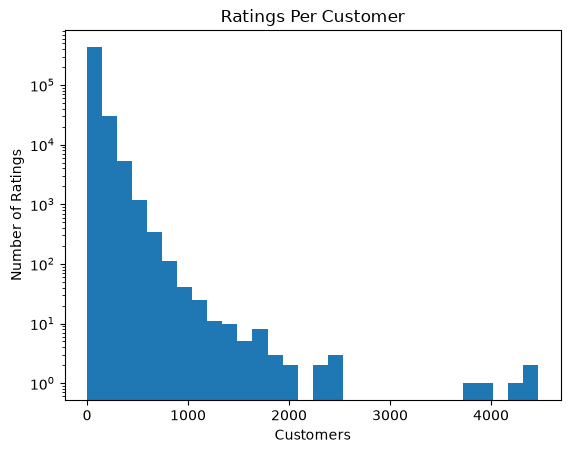

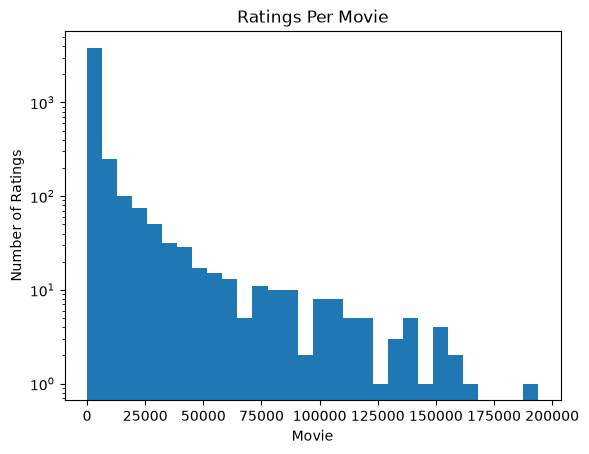

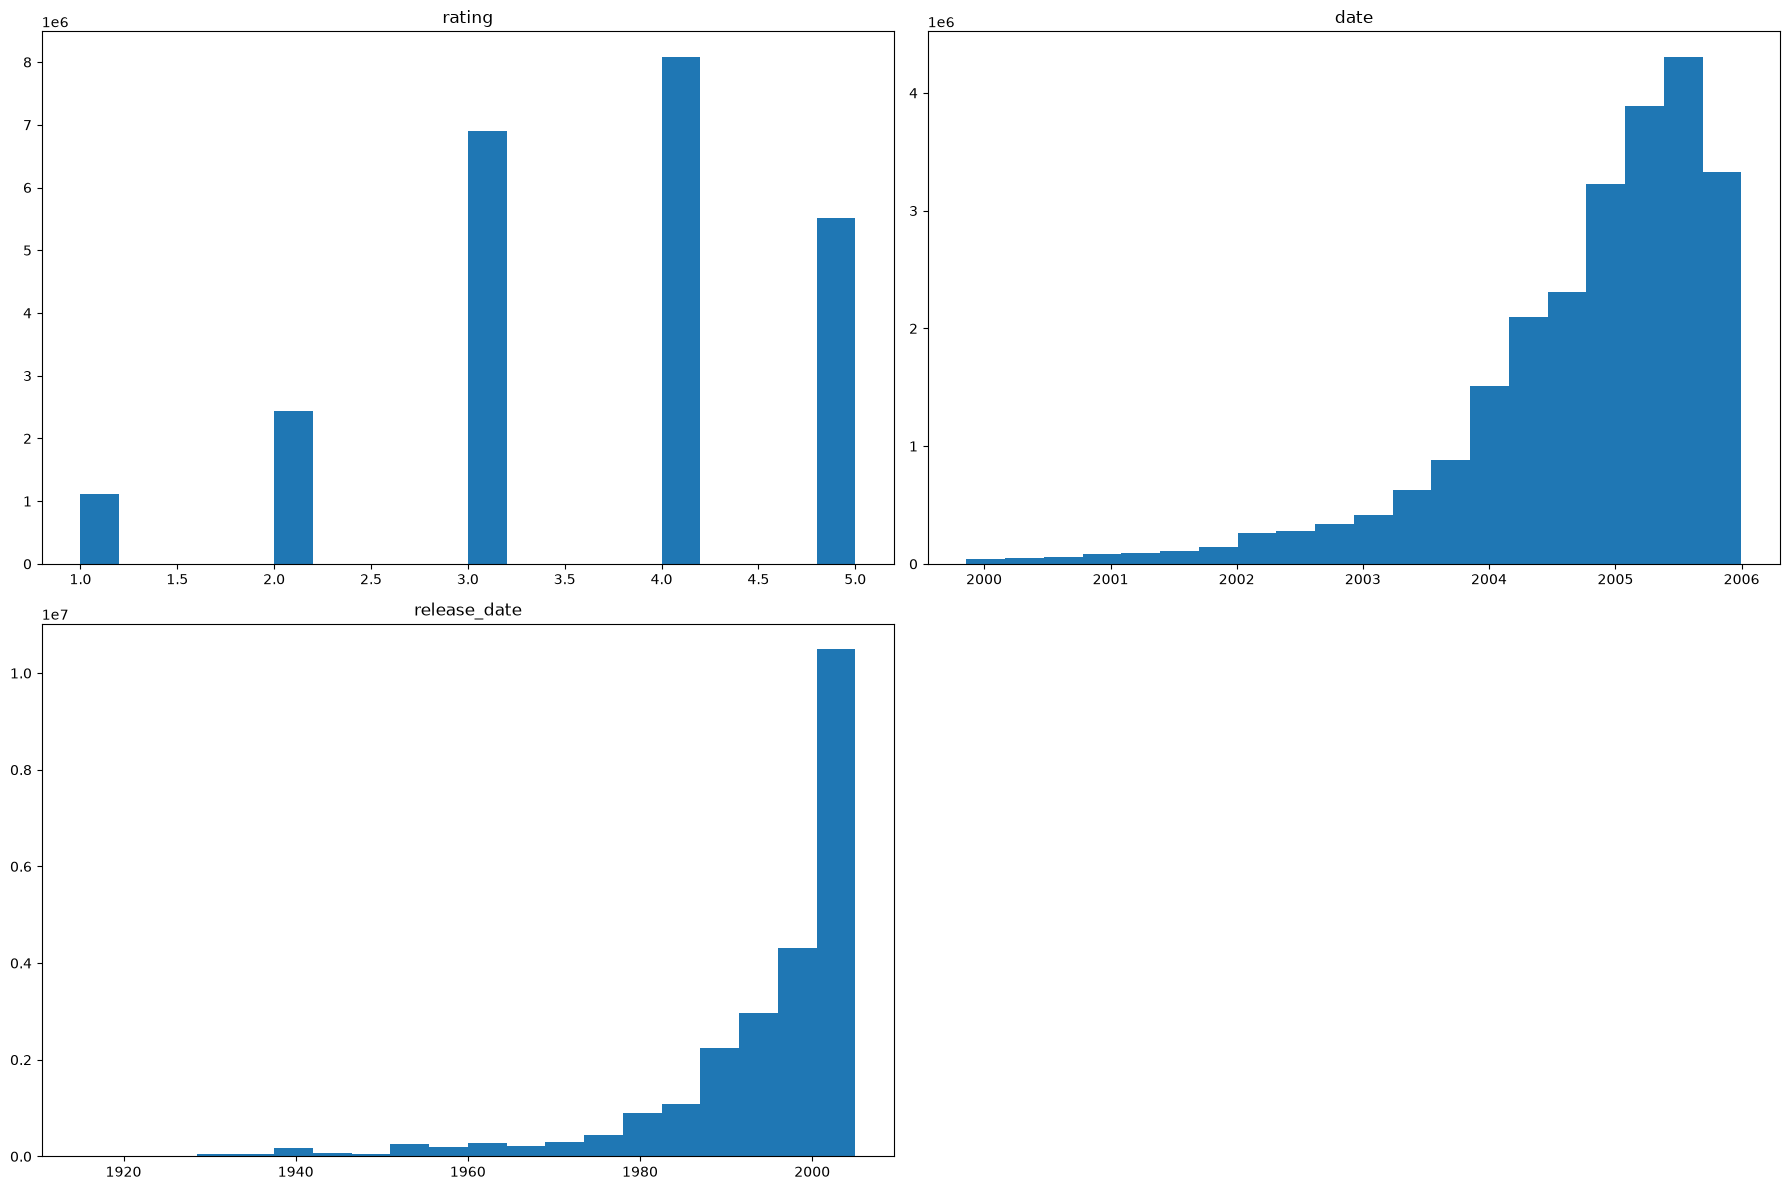

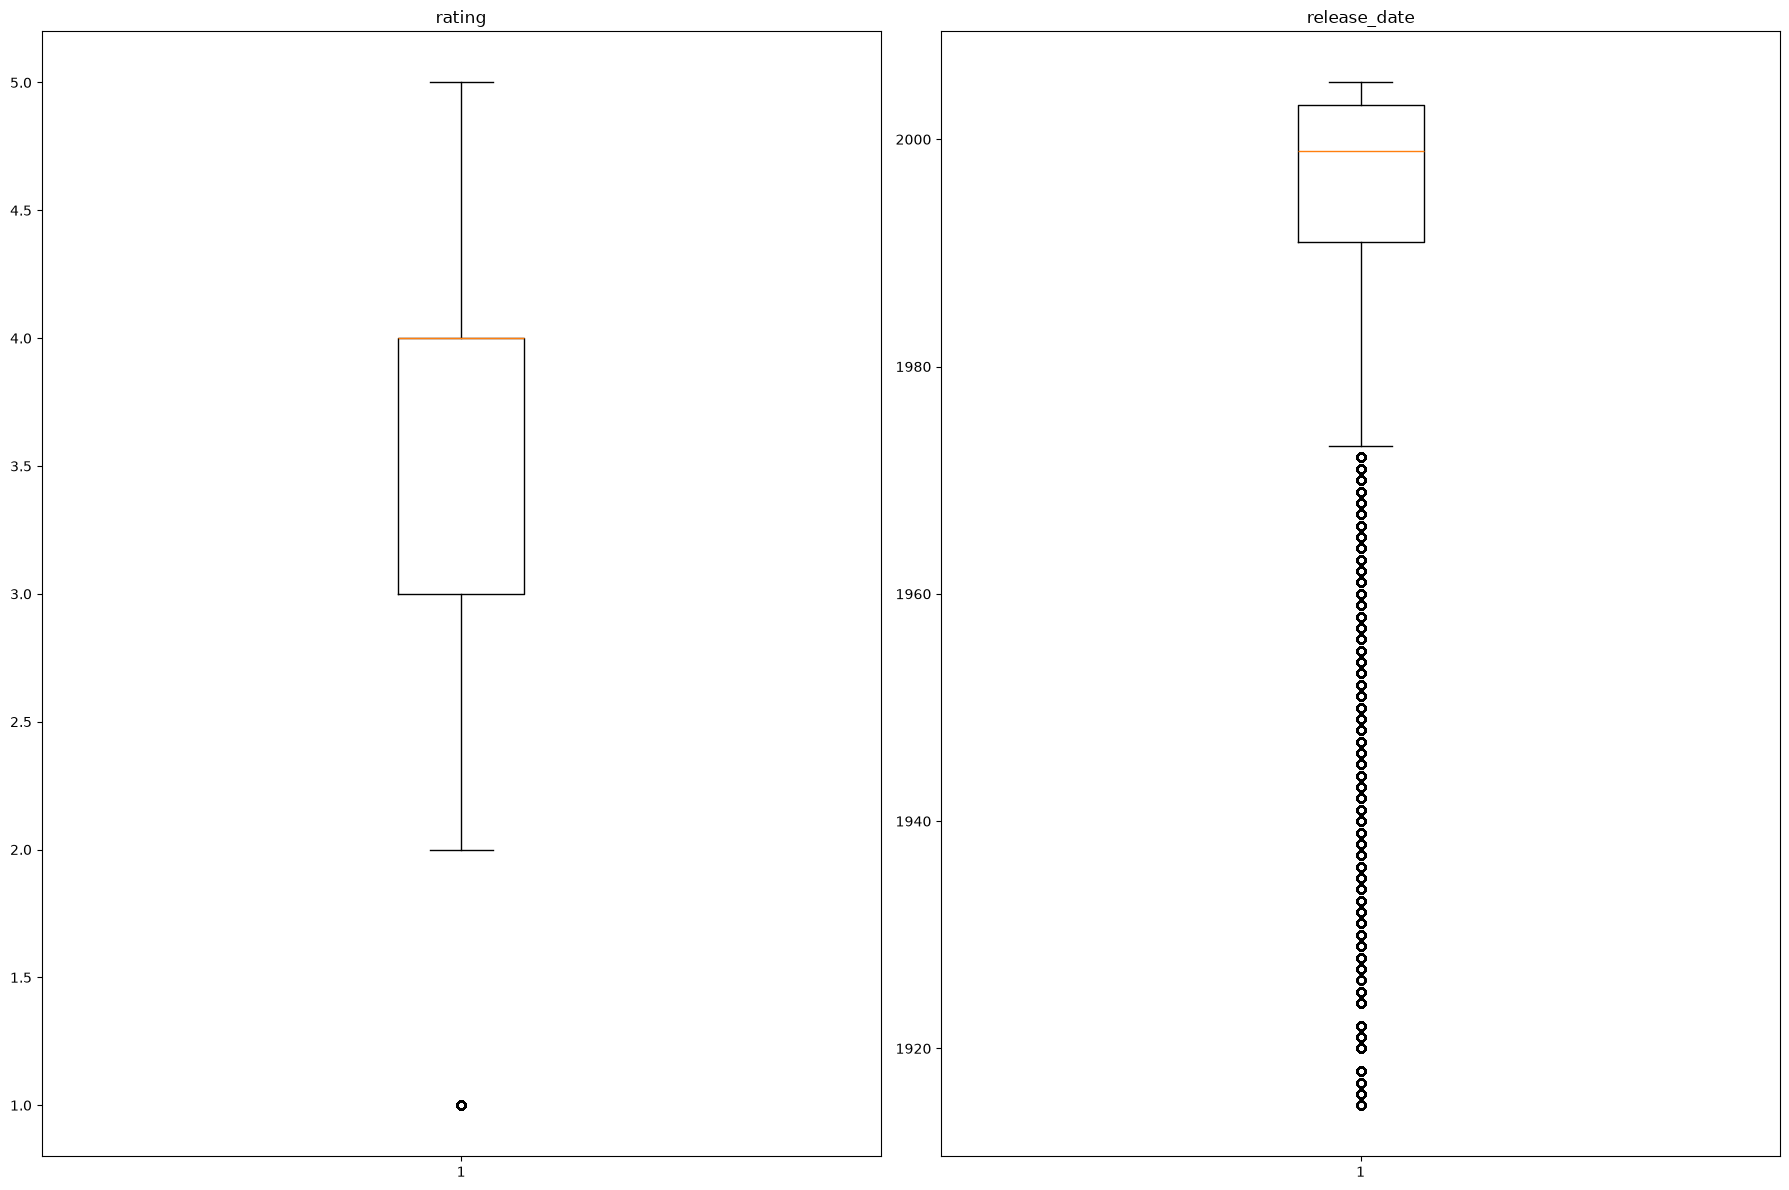

In [8]:
features = ['rating', 'date', 'release_date']
movies_customer = movies.groupby('customer_id').size()
movies_ID = movies.groupby('movie_id').size()

plt.hist(movies_customer, bins=30)
plt.yscale('log')
plt.title('Ratings Per Customer')
plt.xlabel('Customers')
plt.ylabel('Number of Ratings')
plt.show()
plt.hist(movies_ID, bins=30)
plt.yscale('log')
plt.title('Ratings Per Movie')
plt.xlabel('Movie')
plt.ylabel('Number of Ratings')
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.flatten()
for i, col in enumerate(features):
    axes[i].hist(movies[col], bins=20)
    axes[i].set_title(col)
for j in range(len(features), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(18, 12))
axes = axes.flatten()
for i, col in enumerate(['rating', 'release_date']):
    axes[i].boxplot(movies[col])
    axes[i].set_title(col)
for j in range(len(features), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()


## Multivariable Analysis

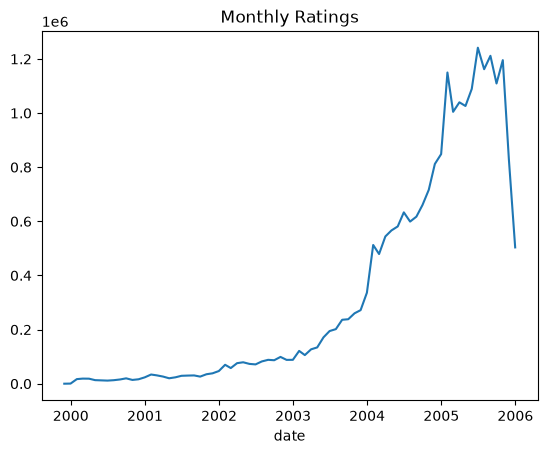

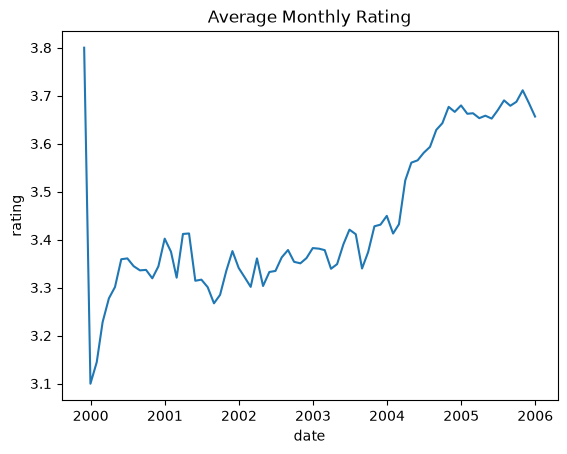

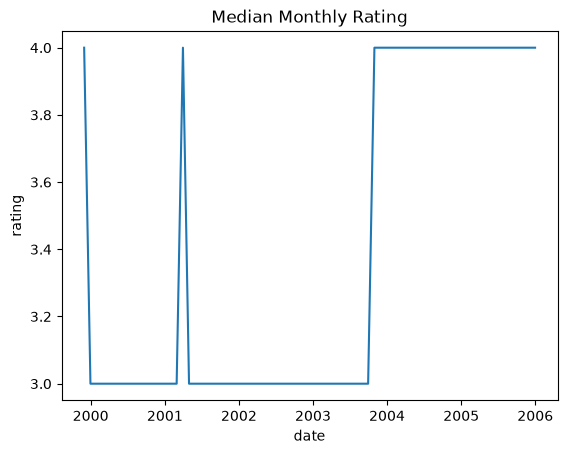

In [9]:
monthly_ratings = movies.set_index('date').resample('ME').size()
sns.lineplot(data=monthly_ratings)
plt.title('Monthly Ratings')
plt.show()

average_rating=monthly_ratings = movies.set_index('date').resample('ME')['rating'].mean()
sns.lineplot(data=average_rating)
plt.title('Average Monthly Rating')
plt.show()

median_rating=monthly_ratings = movies.set_index('date').resample('ME')['rating'].median()
sns.lineplot(data=median_rating)
plt.title('Median Monthly Rating')
plt.show()

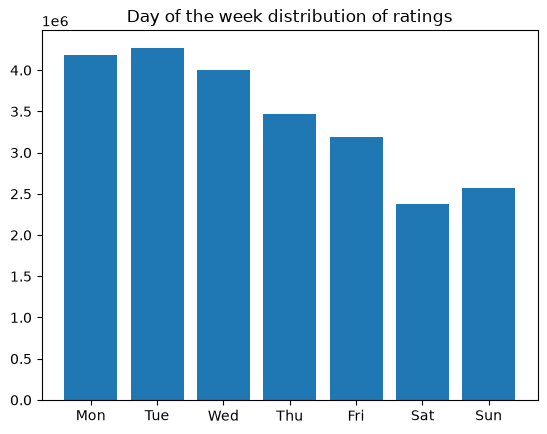

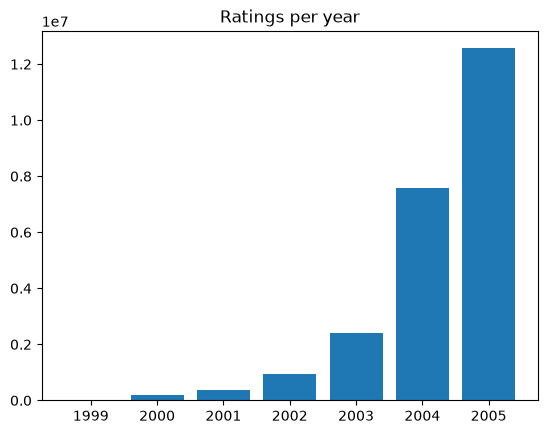

In [10]:
counts = movies['date'].dt.dayofweek.value_counts()
plt.bar(counts.index, counts.values)
plt.title('Day of the week distribution of ratings')
plt.xticks(range(7), ['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
plt.show()

counts = movies['date'].dt.year.value_counts()
plt.bar(counts.index, counts.values)
plt.title('Ratings per year')
plt.show()

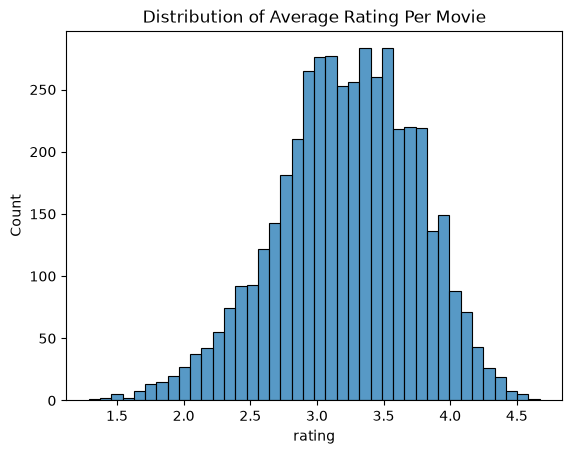

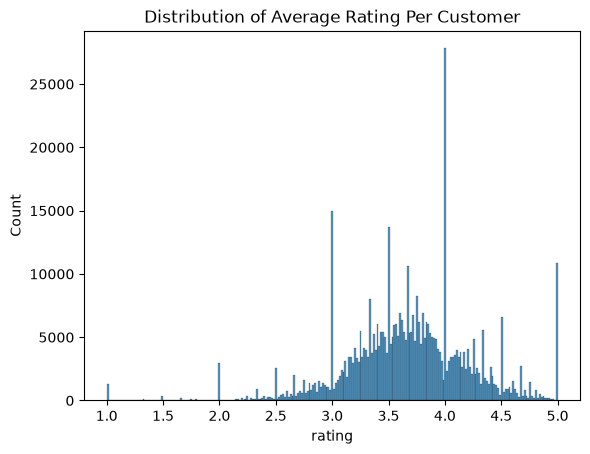

In [13]:
avg_rating_movies = movies.groupby('movie_id')['rating'].mean()
sns.histplot(data=avg_rating_movies)
plt.title('Distribution of Average Rating Per Movie')
plt.show()

avg_rating_customer = movies.groupby('customer_id')['rating'].mean()
sns.histplot(data=avg_rating_customer)
plt.title('Distribution of Average Rating Per Customer')
plt.show()

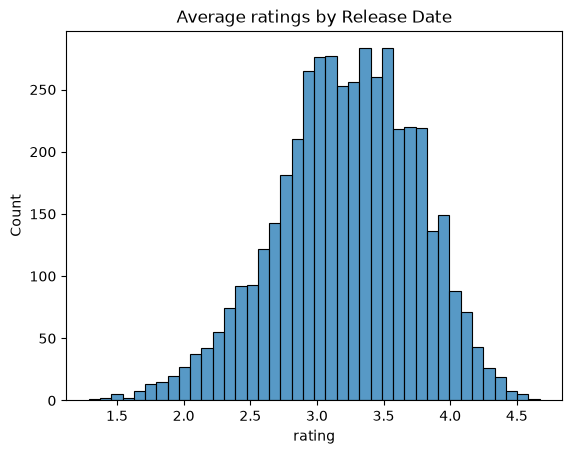

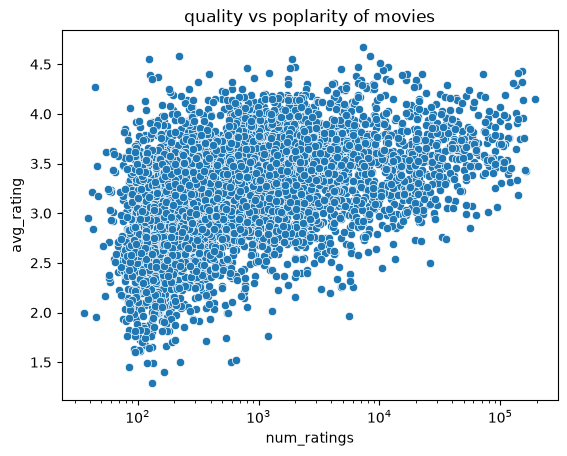

In [20]:
rating_release_date = movies.groupby('release_date')['rating'].mean()
sns.histplot(data=avg_rating_movies)
plt.title('Average ratings by Release Date')
plt.show()

movie_quality_quantity = movies.groupby('movie_id').agg(avg_rating=('rating','mean'), num_ratings=('rating','size'))
sns.scatterplot(data=movie_quality_quantity, x='num_ratings', y='avg_rating')
plt.xscale('log')
plt.title('quality vs poplarity of movies')
plt.show()

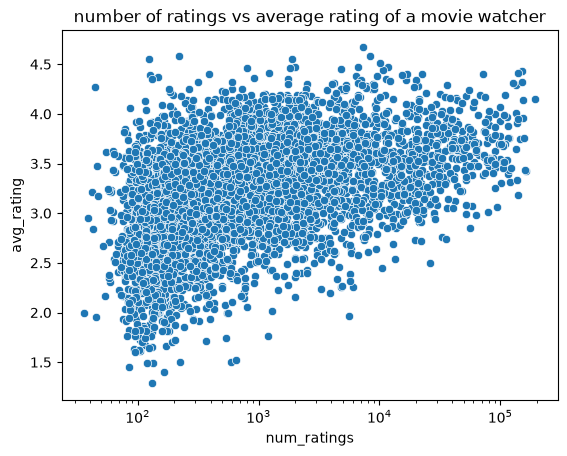

In [32]:
customer_activity = movies.groupby('customer_id').agg(ave_rating=('rating', 'mean'), num_ratings=('rating', 'size'))
sns.scatterplot(data=movie_quality_quantity, x='num_ratings', y='avg_rating')
plt.xscale('log')
plt.title('number of ratings vs average rating of a movie watcher')
plt.show()

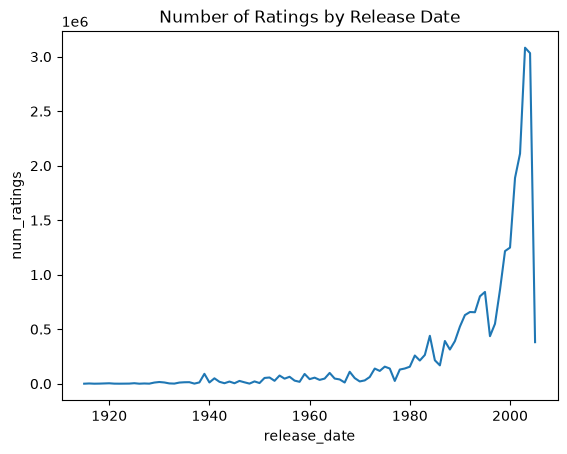

In [27]:
ratings_by_release_date = movies.groupby('release_date')['rating'].size().reset_index(name='num_ratings')
sns.lineplot(data=ratings_by_release_date, x='release_date', y='num_ratings')
plt.title('Number of Ratings by Release Date')
plt.show()

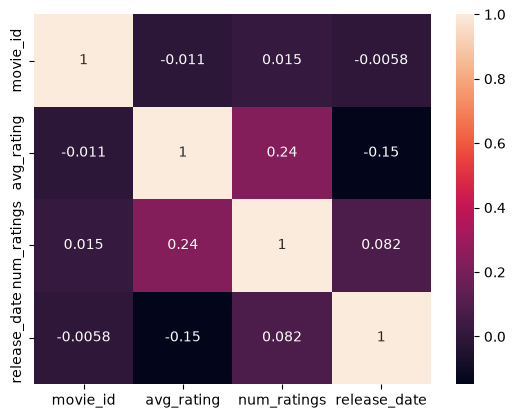

In [29]:
movie_stats = movies.groupby('movie_id').agg(avg_rating=('rating', 'mean'), num_ratings=('rating', 'size'))
movie_stats = movie_stats.merge(titles_df[['movie_id', 'release_date']], on='movie_id')

corr_matrix = movie_stats.corr()
sns.heatmap(corr_matrix, annot=True)
plt.show()

## Models

### Truncated SVD

In [7]:
from scipy.sparse import coo_matrix

test_set = evaluation_df.merge(movies, on=['movie_id', 'customer_id'], how='left')

customer_codes, customer_uniques = pd.factorize(movies['customer_id'])
movie_codes, movie_uniques = pd.factorize(movies['movie_id'])

movies['customer_idx'] = customer_codes
movies['movie_idx'] = movie_codes

n_customers = movies['customer_idx'].nunique()
n_movies = movies['movie_idx'].nunique()

sparse_matrix = coo_matrix(
    (movies['rating'], (movies['customer_idx'], movies['movie_idx'])),
    shape=(n_customers, n_movies)
).tocsr()

customer_id_to_idx = {cust_id: idx for idx, cust_id in enumerate(customer_uniques)}
movie_id_to_idx = {mov_id: idx for idx, mov_id in enumerate(movie_uniques)}

test_set['customer_idx'] = test_set['customer_id'].map(customer_id_to_idx)
test_set['movie_idx'] = test_set['movie_id'].map(movie_id_to_idx)


In [20]:
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import mean_squared_error

n_factors = 50
svd = TruncatedSVD(n_components=n_factors, random_state=42)
customer_factors = svd.fit_transform(sparse_matrix)
movie_factors = svd.components_

test_customer_idx = test_set['customer_idx'].values
test_movie_idx = test_set['movie_idx'].values

predicted_ratings = np.sum(
    customer_factors[test_customer_idx] * movie_factors.T[test_movie_idx],
    axis=1
)

rmse = np.sqrt(mean_squared_error(test_set['rating'], predicted_ratings))
print(f"RMSE: {rmse:.4f}")

RMSE: 3.1801


### K Nearest Neighbor

In [ ]:
from surprise import KNNBaseline
from surprise import Reader, Dataset
from surprise.model_selection import GridSearchCV
from surprise.model_selection import cross_validate

reader = Reader(rating_scale=(1, 5))
data = Dataset.load_from_df(movies[['customer_id', 'movie_id', 'rating']], reader)
'''
param_grid = {'k': list(range(1, 30, 2)), 'sim_options': {'name': ['cosine'], 'user_based': [False]}}
sim_options = {'name': 'cosine','user_based': False }
knn = GridSearchCV(KNNBaseline, param_grid, measures=['rmse', 'mae'], cv=5)


knn.fit(data)
print(knn.best_score['rmse'])
print(knn.best_params['rmse'])
'''
sim_options = {'name': 'pearson_baseline', 'user_based': False}
algo = KNNBaseline(k=20, sim_options=sim_options)
results = cross_validate(algo, data, measures=['RMSE', 'MAE'], cv=3, verbose=True)
print(results['test_rmse'].mean())
print(results['test_mae'].mean())

truncated svd sklearn
truncated svd surprise
knn but with svd embeddings to help with the computation issue
ncf/dnn

In [8]:
movies.to_parquet('movies.parquet')
test_set.to_parquet('test_set.parquet')

ImportError: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - `Import pyarrow` failed. pyarrow is required for parquet support. Use pip or conda to install the pyarrow package.
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip or conda to install the fastparquet package.

In [9]:
import os
print(os.path.getsize(DATA_DIR / 'combined_data_1.txt'))
with open(DATA_DIR / 'combined_data_1.txt') as f:
    print(sum(1 for _ in f))

495032008
24058263


In [ ]:
import os
for f in DATA_DIR.iterdir():
    print(f.name, os.path.getsize(f))


movie_titles.csv 577547
qualifying.txt 52452386
combined_data_2.txt 555207357
combined_data_3.txt 465157779
combined_data_1.txt 495032008
combined_data_4.txt 552537802
README 5916
NetflixRecommenderSystem.ipynb 754721
probe.txt 10782692
